# Dataset B: llimllib/nba_data, Player Salaries and Team Payroll (2015-16 to 2025-26)

This notebook builds the **salary-based** features:

| Feature | Column(s) | Level |
|---|---|---|
| Player salary as % of the salary cap | `salary_pct_of_cap` | player-season-team |
| Luxury-tax markers | `over_cap`, `over_tax`, `over_first_apron`, `over_second_apron`, `tax_tier` | team-season |
| Dollars above/below each threshold | `dollars_vs_cap`, `dollars_vs_tax`, `dollars_vs_first_apron`, `dollars_vs_second_apron` (plus `_pct_cap` versions) | team-season |

The team-season features are also attached to every player row, so the output already has the project's unit: **one row = one player + season + team**.

*Run order: `01` → `02` → `03` → `999`. This notebook reads `cap_thresholds_clean.csv` from notebook 01.*

- **Dataset name:** llimllib/nba_data, a public DuckDB/parquet catalog of NBA data rebuilt every 4 hours
- **Link:** https://github.com/llimllib/nba_data (data is served from `https://basketball-data.billmill.org/nba/nba.duckdb`)
- **Tables used:**
  - `bbref_salaries`: each player's salary with each team in each season, scraped from Basketball-Reference team pages. Columns: `season`, `team_id`, `bbref_id`, `player_id`, `salary`.
  - `team_seasons`: NBA `team_id` → abbreviation lookup.
  - `players`: NBA `player_id` → player name lookup.
- **Saved as:** `data-files/00-raw/llimllib_bbref_salaries_raw.csv`, `llimllib_team_seasons_raw.csv`, `llimllib_players_raw.csv` (downloaded below if missing)

## Important variables

| Variable | Units | Meaning |
|---|---|---|
| `season` | year | The year the season **ends** (2026 = 2025-26). Same convention as our other notebooks. |
| `team_id` | text | NBA team id (e.g. `1610612744` = Golden State). Converted to a 3-letter abbreviation for joining. |
| `bbref_id` | text | Basketball-Reference player id (e.g. `curryst01`). Always present. |
| `player_id` | text | NBA.com person id (e.g. `201939`). This is the best key for joining to NBA stats data. |
| `salary` | USD (nominal) | The player's salary with that team that season. Per the data dictionary, **two-way contracts have a blank salary**. |

## Concerns going in

1. **The repo has no contract terms** (length, options, guarantees). Years remaining comes from ESPN in notebook 03.
2. **Is a traded player counted on both teams?** If he were, team payroll would be double counted. We test this in section 3E.

## Setup

In [1]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nba_cleaning_utils import RAW, PROCESSED, FIRST_SEASON, LAST_SEASON, normalize_name

## 1. Download (skipped if the raw files already exist)

DuckDB reads the remote catalog over HTTPS and only downloads the parquet files a query needs. We save the raw tables as CSV so the rest of the notebook runs offline.

In [2]:
RAW_SAL = RAW / 'llimllib_bbref_salaries_raw.csv'
RAW_TEAMS = RAW / 'llimllib_team_seasons_raw.csv'
RAW_PLAYERS = RAW / 'llimllib_players_raw.csv'

if not (RAW_SAL.exists() and RAW_TEAMS.exists() and RAW_PLAYERS.exists()):
    con = duckdb.connect()
    con.sql('INSTALL httpfs; LOAD httpfs;')
    con.sql("ATTACH 'https://basketball-data.billmill.org/nba/nba.duckdb' AS nba (READ_ONLY)")
    con.sql('SELECT * FROM nba.bbref_salaries ORDER BY season, team_id, bbref_id').df().to_csv(RAW_SAL, index=False)
    con.sql('SELECT * FROM nba.team_seasons ORDER BY season, team_id').df().to_csv(RAW_TEAMS, index=False)
    con.sql('SELECT * FROM nba.players ORDER BY player_id').df().to_csv(RAW_PLAYERS, index=False)
    print('downloaded the three tables')
else:
    print('raw files already present, skipping download')

raw files already present, skipping download


## 2. Load the data

In [3]:
ids = {'team_id': str, 'player_id': str, 'bbref_id': str}
salaries_raw = pd.read_csv(RAW_SAL, dtype=ids)
team_seasons = pd.read_csv(RAW_TEAMS, dtype=ids)
players = pd.read_csv(RAW_PLAYERS, dtype=ids)

salaries_raw.head()

,season,team_id,bbref_id,player_id,salary
0,2010,1610612737,bibbymi01,1710,6217617.0
1,2010,1610612737,collija04,2215,1181803.0
2,2010,1610612737,crawfja01,2037,9360000.0
3,2010,1610612737,evansma01,2230,2500000.0
4,2010,1610612737,horfoal01,201143,4307640.0


In [4]:
team_seasons.head(3)

,season,team_id,nba_abbrev,full_name,is_nba
0,2010,12303,MTA,Tel Aviv Maccabi Elite,False
1,2010,12315,RMA,Real Madrid Real Madrid,False
2,2010,12319,PAR,Belegrade Partizan,False


In [5]:
players.head(3)

,player_id,name,first_season,last_season
0,101106,Andrew Bogut,2010,2019
1,101107,Marvin Williams,2010,2020
2,101108,Chris Paul,2010,2026


## 3A. Is the data tidy?

In [6]:
salaries_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10408 entries, 0 to 10407
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   season     10408 non-null  int64  
 1   team_id    10408 non-null  str    
 2   bbref_id   10408 non-null  str    
 3   player_id  10036 non-null  str    
 4   salary     9979 non-null   float64
dtypes: float64(1), int64(1), str(3)
memory usage: 406.7 KB


**What we found:** The salary table is tidy and already in long format: one row per player, team, and season, with one variable per column. `salary` is a float only because of blanks. The values are whole dollars. Names and team abbreviations are in separate lookup tables (normalized like a database), so we will join them in.

## 3B. Size of the data

In [7]:
print('rows, columns:', salaries_raw.shape)
print('seasons available (end year):', salaries_raw['season'].min(), 'to', salaries_raw['season'].max())
salaries_raw.groupby('season').size().rename('rows').to_frame().T

rows, columns: (10408, 5)
seasons available (end year): 2010 to 2027


season,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,2027
rows,474,467,469,497,426,560,564,610,651,625,614,614,747,632,673,654,671,460


In [8]:
sal = salaries_raw.query('@FIRST_SEASON <= season <= @LAST_SEASON').copy()
print('rows in our 2015-16 to 2025-26 window:', len(sal))
print('teams:', sal['team_id'].nunique(), '| different players (bbref_id):', sal['bbref_id'].nunique())

rows in our 2015-16 to 2025-26 window: 7055
teams: 30 | different players (bbref_id): 1665


The source covers 2009-10 through the current 2026-27 season, which is still in progress. We keep our 11 seasons, **2016-2026 in end years**: about 7,000 salary rows for 30 teams and roughly 1,650 players. The partial 2026-27 season is dropped.

## 3C. Join team abbreviations and player names

In [9]:
nba_teams = team_seasons.query('is_nba')[['season', 'team_id', 'nba_abbrev']]
sal = sal.merge(nba_teams, on=['season', 'team_id'], how='left', validate='many_to_one')
sal = sal.merge(players[['player_id', 'name']], on='player_id', how='left', validate='many_to_one')

print('rows with no team abbreviation:', sal['nba_abbrev'].isna().sum())
print('team abbreviations:', sorted(sal['nba_abbrev'].unique()))

rows with no team abbreviation: 0
team abbreviations: ['ATL', 'BKN', 'BOS', 'CHA', 'CHI', 'CLE', 'DAL', 'DEN', 'DET', 'GSW', 'HOU', 'IND', 'LAC', 'LAL', 'MEM', 'MIA', 'MIL', 'MIN', 'NOP', 'NYK', 'OKC', 'ORL', 'PHI', 'PHX', 'POR', 'SAC', 'SAS', 'TOR', 'UTA', 'WAS']


## 3D. Missing data

In [10]:
sal[['player_id', 'name', 'salary']].isna().sum()

player_id    288
name         288
salary       428
dtype: int64

In [11]:
missing = pd.DataFrame({
    'rows': sal.groupby('season').size(),
    'salary blank': sal[sal['salary'].isna()].groupby('season').size(),
    'salary = 0': sal[sal['salary'] == 0].groupby('season').size(),
    'no NBA player_id': sal[sal['player_id'].isna()].groupby('season').size(),
}).fillna(0).astype(int)
missing

,rows,salary blank,salary = 0,no NBA player_id
season,,,,
2016,564,0,0,14
2017,610,0,0,26
2018,651,0,72,38
2019,625,0,47,39
2020,614,0,53,34
2021,614,0,63,27
2022,747,0,69,30
2023,632,84,0,15
2024,673,109,0,26


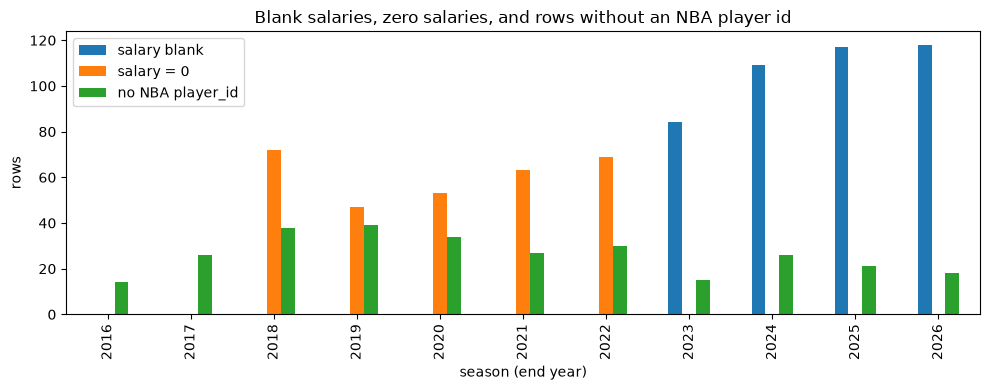

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
missing[['salary blank', 'salary = 0', 'no NBA player_id']].plot(kind='bar', ax=ax)
ax.set_xlabel('season (end year)')
ax.set_ylabel('rows')
ax.set_title('Blank salaries, zero salaries, and rows without an NBA player id')
plt.tight_layout()
plt.show()

In [13]:
# Who are the rows with no NBA player_id? Mostly very small salaries (10-day deals, waived players).
no_id = sal[sal['player_id'].isna()]
print('median salary, rows with no NBA id:  ', f"${no_id['salary'].median():,.0f}")
print('median salary, rows with an NBA id:  ', f"${sal.loc[sal['player_id'].notna(), 'salary'].median():,.0f}")
print('share of all salary dollars in no-id rows:', f"{no_id['salary'].sum() / sal['salary'].sum():.1%}")
no_id.sample(6, random_state=0)

median salary, rows with no NBA id:   $1,000,000
median salary, rows with an NBA id:   $2,665,740
share of all salary dollars in no-id rows: 1.2%


,season,team_id,bbref_id,player_id,salary,nba_abbrev,name
1460,2018,1610612749,mooreja02,NaN,0.0,MIL,NaN
3728,2022,1610612738,yabusgu01,NaN,1039080.0,BOS,NaN
2096,2019,1610612749,teletmi01,NaN,3500000.0,MIL,NaN
4453,2023,1610612738,jacksde01,NaN,92857.0,BOS,NaN
6697,2026,1610612751,muokada01,NaN,85300.0,BKN,NaN
1350,2018,1610612744,thompja02,NaN,945126.0,GSW,NaN


**What we found:**

- **Blank salaries (2023-24 on) and zero salaries (2017-18 to 2021-22) never appear in the same season.** They are the same kind of row recorded two different ways: **two-way contracts**. The data dictionary says two-way contracts have blank salaries, and two-way deals began in 2017-18, which is exactly when the zeros start. Two-way pay does **not** count against the cap, so for cap purposes the right value is **\$0**. We will set `cap_salary = 0` and add an `is_two_way` flag.
- **About 4% of rows have no NBA `player_id`, so no name either.** The source couldn't match these Basketball-Reference players to an NBA id. They skew toward smaller contracts (median about \$1.0M vs. \$2.7M) and hold only about 1% of all salary dollars, but a few are real rotation players (e.g., Guerschon Yabusele, BOS 2021-22). **We drop these rows entirely.** Without an id or name they can't be joined to player stats. Dropping them also removes their salary from team payroll, so payrolls come out about 1% low on average. The markers can only change for teams sitting right at a threshold.

## 3E. Outliers and suspicious entries

**(a) Is a traded player listed on both teams?** We check stars traded mid-season. If each one appears only under his final team, payroll isn't being double counted.

In [14]:
pd.set_option('display.float_format', '{:,.0f}'.format)
traded_midseason = {          # (bbref_id, season): what happened
    ('duranke01', 2023): 'BKN -> PHX, Feb 2023',
    ('hardeja01', 2024): 'PHI -> LAC, Nov 2023',
    ('siakapa01', 2024): 'TOR -> IND, Jan 2024',
    ('doncilu01', 2025): 'DAL -> LAL, Feb 2025',
    ('hardeja01', 2026): 'LAC -> CLE, Feb 2026',
}
check = pd.concat([sal[(sal['bbref_id'] == b) & (sal['season'] == s)].assign(trade=t)
                   for (b, s), t in traded_midseason.items()])
check[['season', 'name', 'trade', 'nba_abbrev', 'salary']]

,season,name,trade,nba_abbrev,salary
4812,2023,Kevin Durant,"BKN -> PHX, Feb 2023",PHX,"44,119,845"
5243,2024,James Harden,"PHI -> LAC, Nov 2023",LAC,"35,680,595"
5415,2024,Pascal Siakam,"TOR -> IND, Jan 2024",IND,"37,893,408"
5937,2025,Luka Dončić,"DAL -> LAL, Feb 2025",LAL,"43,031,940"
6434,2026,James Harden,"LAC -> CLE, Feb 2026",CLE,"39,446,090"


In [15]:
# Player-seasons with rows on 2+ teams: what do they look like?
teams_per = sal.groupby(['season', 'bbref_id'])['team_id'].transform('nunique')
multi = sal[teams_per > 1]
print('player-seasons with rows on 2+ teams:', multi.groupby(['season', 'bbref_id']).ngroups)
same_salary = multi.groupby(['season', 'bbref_id'])['salary'].nunique().eq(1).sum()
print('...of which every row has the same salary (a sign of double counting):', same_salary)
multi[multi['bbref_id'] == 'lillada01'][['season', 'name', 'nba_abbrev', 'salary']]

player-seasons with rows on 2+ teams: 496
...of which every row has the same salary (a sign of double counting): 59


,season,name,nba_abbrev,salary
6646,2026,Damian Lillard,MIL,"22,516,603"
6833,2026,Damian Lillard,POR,"14,104,000"


**What we found:** Each traded star appears **once, under the team he finished the season with**, for his full-season salary. So this table is an end-of-season payroll snapshot, and trades are **not** double counted.

The ~500 player-seasons with rows on 2+ teams are a different case: **waived players whose old team still pays them**. Damian Lillard in 2025-26 is an example: Milwaukee pays \$22.5M of dead money and Portland pays his new contract. That money really does count against both caps, so we keep every row when we sum payroll. Only a few dozen of these have identical salaries on both teams, and those are almost all pro-rated minimum deals that happen to match.

**(b) Extreme salaries.**

In [16]:
sal.loc[sal.groupby('season')['salary'].idxmax(), ['season', 'name', 'nba_abbrev', 'salary']]

,season,name,nba_abbrev,salary
189,2016,Kobe Bryant,LAL,"25,000,000"
608,2017,LeBron James,CLE,"30,963,450"
1340,2018,Stephen Curry,GSW,"34,682,550"
1978,2019,Stephen Curry,GSW,"37,457,154"
2593,2020,Stephen Curry,GSW,"40,231,758"
3202,2021,Stephen Curry,GSW,"43,006,362"
3855,2022,Stephen Curry,GSW,"45,780,966"
4562,2023,Stephen Curry,GSW,"48,070,014"
5199,2024,Stephen Curry,GSW,"51,915,615"
5877,2025,Stephen Curry,GSW,"55,761,216"


In [17]:
tiny = sal[(sal['salary'] > 0) & (sal['salary'] < 100_000)]
print('rows with a salary between $1 and $99,999:', len(tiny))
tiny.sample(5, random_state=1)[['season', 'name', 'nba_abbrev', 'salary']]

rows with a salary between $1 and $99,999: 406


,season,name,nba_abbrev,salary
5591,2024,Malik Williams,TOR,"77,212"
670,2017,Quinn Cook,DAL,"31,969"
4370,2022,Jordan Schakel,WAS,"53,176"
961,2017,James Webb III,PHI,"65,000"
1651,2018,Nigel Hayes-Davis,SAC,"55,296"


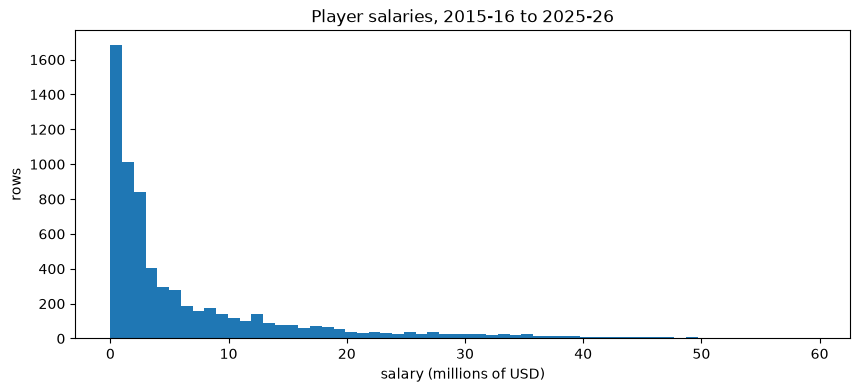

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(sal['salary'].dropna() / 1e6, bins=60)
ax.set_xlabel('salary (millions of USD)')
ax.set_ylabel('rows')
ax.set_title('Player salaries, 2015-16 to 2025-26')
plt.show()

- **The top salary each season is the expected supermax player** (Curry, LeBron, etc.), rising with the cap to about \$60M. These are real values, not errors.
- **Salaries under \$100K are real.** They are 10-day contracts and partial guarantees. They are tiny shares of the cap, so we keep them.
- **The distribution is very right-skewed** (most players earn under \$5M). XGBoost's tree splits handle skew without transformation.

## 4. Clean the data

In [19]:
cap = pd.read_csv(PROCESSED / 'cap_thresholds_clean.csv')

# Drop rows with no NBA player id (see 3D)
print('dropping rows with no NBA player_id:', sal['player_id'].isna().sum())
clean = (sal[sal['player_id'].notna()]
         .rename(columns={'nba_abbrev': 'team', 'name': 'player_name', 'player_id': 'nba_player_id'})
         .copy())

# Two-way contracts: blank (2023+) or 0 (2018-2022). They don't count against the cap.
clean['is_two_way'] = clean['salary'].isna() | clean['salary'].eq(0)
clean['cap_salary'] = clean['salary'].fillna(0).astype('int64')

clean = clean.merge(cap[['season', 'salary_cap']], on='season', how='left', validate='many_to_one')
clean['salary_pct_of_cap'] = clean['cap_salary'] / clean['salary_cap'] * 100
clean['name_key'] = clean['player_name'].map(normalize_name)

clean[['season', 'team', 'player_name', 'cap_salary', 'is_two_way', 'salary_pct_of_cap']].head()

dropping rows with no NBA player_id: 288


,season,team,player_name,cap_salary,is_two_way,salary_pct_of_cap
0,2016,ATL,Kent Bazemore,2000000,False,3
1,2016,ATL,Tim Hardaway Jr.,1304520,False,2
2,2016,ATL,Kirk Hinrich,2870000,False,4
3,2016,ATL,Al Horford,12000000,False,17
4,2016,ATL,Kris Humphries,388025,False,1


### Team payroll and luxury-tax features

Team payroll = the sum of `cap_salary` over every remaining row for that team and season. That includes dead money for waived players and 10-day deals, since both count against the cap. Then we compare payroll with each threshold:

- **Markers**: `over_cap`, `over_tax`, `over_first_apron`, `over_second_apron` (the last one is blank before 2023-24, when the second apron didn't exist).
- **`tax_tier`**: one ordered number, 0 = under the cap, 1 = over the cap, 2 = over the tax line, 3 = over the first apron, 4 = over the second apron.
- **Dollars above/below each line**: `dollars_vs_cap = payroll - cap`, and so on. Positive means over the line and negative means room under it. The `_pct_cap` versions divide by the cap, so values are comparable across seasons with very different caps.

In [20]:
payroll = (clean.groupby(['season', 'team'], as_index=False)
                .agg(team_payroll=('cap_salary', 'sum'), roster_rows=('bbref_id', 'size'))
                .merge(cap, on='season', how='left', validate='many_to_one'))

lines = {'cap': 'salary_cap', 'tax': 'luxury_tax_line', 'first_apron': 'first_apron', 'second_apron': 'second_apron'}
for name, col in lines.items():
    line = payroll[col].astype('Float64')
    payroll[f'dollars_vs_{name}'] = payroll['team_payroll'] - line
    payroll[f'dollars_vs_{name}_pct_cap'] = payroll[f'dollars_vs_{name}'] / payroll['salary_cap'] * 100
    payroll[f'over_{name}'] = payroll[f'dollars_vs_{name}'] > 0      # stays <NA> when the line doesn't exist

payroll['tax_tier'] = (payroll[['over_cap', 'over_tax', 'over_first_apron', 'over_second_apron']]
                       .fillna(False).astype(int).sum(axis=1))
payroll['payroll_pct_of_cap'] = payroll['team_payroll'] / payroll['salary_cap'] * 100

payroll.head()

,season,team,team_payroll,roster_rows,season_label,salary_cap,luxury_tax_line,first_apron,second_apron,has_second_apron,...,dollars_vs_tax_pct_cap,over_tax,dollars_vs_first_apron,dollars_vs_first_apron_pct_cap,over_first_apron,dollars_vs_second_apron,dollars_vs_second_apron_pct_cap,over_second_apron,tax_tier,payroll_pct_of_cap
0,2016,ATL,71453126,16,2015-16,70000000,84740000,88740000,NaN,False,...,-19,False,"-17,286,874",-25,False,<NA>,<NA>,<NA>,1,102
1,2016,BKN,83831503,20,2015-16,70000000,84740000,88740000,NaN,False,...,-1,False,"-4,908,497",-7,False,<NA>,<NA>,<NA>,1,120
2,2016,BOS,75151919,21,2015-16,70000000,84740000,88740000,NaN,False,...,-14,False,"-13,588,081",-19,False,<NA>,<NA>,<NA>,1,107
3,2016,CHA,77609865,16,2015-16,70000000,84740000,88740000,NaN,False,...,-10,False,"-11,130,135",-16,False,<NA>,<NA>,<NA>,1,111
4,2016,CHI,85385898,15,2015-16,70000000,84740000,88740000,NaN,False,...,1,True,"-3,354,102",-5,False,<NA>,<NA>,<NA>,2,122


### Check the team payrolls

In [21]:
pd.set_option('display.float_format', '{:,.2f}'.format)
summary = payroll.groupby('season').agg(
    median_payroll_M=('team_payroll', lambda x: x.median() / 1e6),
    teams_over_cap=('over_cap', 'sum'),
    teams_over_tax=('over_tax', 'sum'),
    teams_over_first_apron=('over_first_apron', 'sum'),
    teams_over_second_apron=('over_second_apron', 'sum'),
)
summary

,median_payroll_M,teams_over_cap,teams_over_tax,teams_over_first_apron,teams_over_second_apron
season,,,,,
2016,74.44,24,8,5,0
2017,98.27,18,2,1,0
2018,108.79,21,4,3,0
2019,118.27,27,8,3,0
2020,123.53,30,4,0,0
2021,127.30,26,5,3,0
2022,133.70,29,8,7,0
2023,148.86,28,9,9,0
2024,161.01,27,10,7,4


In [22]:
# A sanity check: teams must spend at least 90% of the cap (the salary floor), or pay the shortfall.
below_floor = payroll[payroll['team_payroll'] < 0.9 * payroll['salary_cap']]
print('team-seasons below the 90% salary floor:', len(below_floor), 'of', len(payroll))
below_floor[['season', 'team', 'team_payroll', 'salary_cap', 'payroll_pct_of_cap']]

team-seasons below the 90% salary floor: 13 of 330


,season,team,team_payroll,salary_cap,payroll_pct_of_cap
22,2016,PHI,53540542,70000000,76.49
24,2016,POR,61000674,70000000,87.14
31,2017,BKN,83727571,94143000,88.94
37,2017,DEN,80373997,94143000,85.37
47,2017,MIN,72261074,94143000,76.76
52,2017,PHI,73790855,94143000,78.38
58,2017,UTA,80598193,94143000,85.61
66,2018,DAL,85820476,99093000,86.61
96,2019,DAL,76648624,101869000,75.24
169,2021,NYK,91469893,109140000,83.81


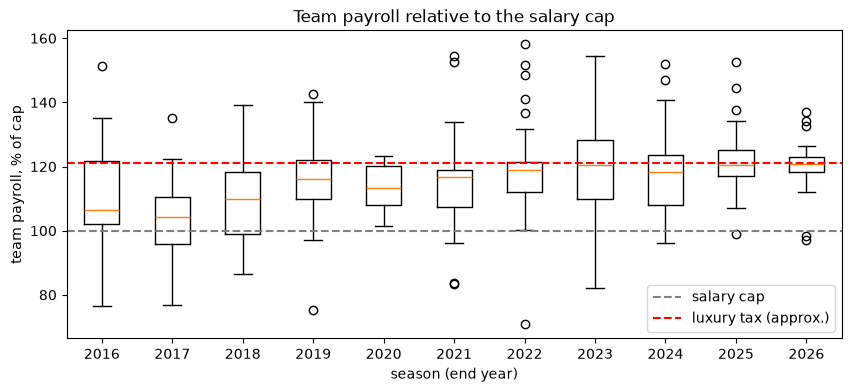

In [23]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([payroll.loc[payroll['season'] == s, 'payroll_pct_of_cap'] for s in sorted(payroll['season'].unique())],
           tick_labels=sorted(payroll['season'].unique()))
ax.axhline(100, color='gray', linestyle='--', label='salary cap')
ax.axhline(payroll['luxury_tax_line'].div(payroll['salary_cap']).mean() * 100, color='red', linestyle='--', label='luxury tax (approx.)')
ax.set_xlabel('season (end year)')
ax.set_ylabel('team payroll, % of cap')
ax.set_title('Team payroll relative to the salary cap')
ax.legend()
plt.show()

**What we found:**

- **Most teams are over the cap every year, and 2-12 teams are over the tax line each season.** That matches what we'd expect. The 2016-17 cap spike shows up as a season where many teams suddenly had room under the cap.
- **The second apron only exists for 2023-24 on, and a handful of teams are above it each season.** Before that the marker is blank (`<NA>`), not `False`.
- **A few team-seasons fall below the 90% salary floor.** That is allowed (the team pays the shortfall to its players at season end), and it mostly happens to rebuilding teams. It isn't a data error.

### Build the player-level table

In [24]:
team_cols = ['team_payroll', 'payroll_pct_of_cap', 'tax_tier',
             'over_cap', 'over_tax', 'over_first_apron', 'over_second_apron',
             'dollars_vs_cap', 'dollars_vs_tax', 'dollars_vs_first_apron', 'dollars_vs_second_apron',
             'dollars_vs_cap_pct_cap', 'dollars_vs_tax_pct_cap', 'dollars_vs_first_apron_pct_cap', 'dollars_vs_second_apron_pct_cap']

player_features = (
    clean
    .merge(payroll[['season', 'team'] + team_cols], on=['season', 'team'], how='left', validate='many_to_one')
    [['season', 'team', 'nba_player_id', 'bbref_id', 'player_name', 'name_key',
      'cap_salary', 'is_two_way', 'salary_pct_of_cap'] + team_cols]
    .sort_values(['season', 'team', 'cap_salary'], ascending=[True, True, False])
    .reset_index(drop=True)
)

# One row per player + season + team
assert not player_features.duplicated(['season', 'team', 'nba_player_id']).any()
print(player_features.shape)
player_features.head()

(6767, 24)


,season,team,nba_player_id,bbref_id,player_name,name_key,cap_salary,is_two_way,salary_pct_of_cap,team_payroll,...,over_first_apron,over_second_apron,dollars_vs_cap,dollars_vs_tax,dollars_vs_first_apron,dollars_vs_second_apron,dollars_vs_cap_pct_cap,dollars_vs_tax_pct_cap,dollars_vs_first_apron_pct_cap,dollars_vs_second_apron_pct_cap
0,2016,ATL,200794,millspa01,Paul Millsap,paul millsap,19000000,False,27.14,71453126,...,False,<NA>,"1,453,126.00","-13,286,874.00","-17,286,874.00",<NA>,2.08,-18.98,-24.70,<NA>
1,2016,ATL,201143,horfoal01,Al Horford,al horford,12000000,False,17.14,71453126,...,False,<NA>,"1,453,126.00","-13,286,874.00","-17,286,874.00",<NA>,2.08,-18.98,-24.70,<NA>
2,2016,ATL,201168,splitti01,Tiago Splitter,tiago splitter,8500000,False,12.14,71453126,...,False,<NA>,"1,453,126.00","-13,286,874.00","-17,286,874.00",<NA>,2.08,-18.98,-24.70,<NA>
3,2016,ATL,201952,teaguje01,Jeff Teague,jeff teague,8000000,False,11.43,71453126,...,False,<NA>,"1,453,126.00","-13,286,874.00","-17,286,874.00",<NA>,2.08,-18.98,-24.70,<NA>
4,2016,ATL,2594,korveky01,Kyle Korver,kyle korver,5746479,False,8.21,71453126,...,False,<NA>,"1,453,126.00","-13,286,874.00","-17,286,874.00",<NA>,2.08,-18.98,-24.70,<NA>


In [25]:
player_features[['salary_pct_of_cap', 'payroll_pct_of_cap', 'dollars_vs_tax']].describe()

,salary_pct_of_cap,payroll_pct_of_cap,dollars_vs_tax
count,"6,767.00","6,767.00","6,767.00"
mean,5.62,114.83,"-6,515,919.12"
std,7.75,14.43,"15,772,322.93"
min,0.00,70.75,"-57,073,593.00"
25%,0.58,105.69,"-16,098,978.00"
50%,2.14,116.72,"-5,511,804.00"
75%,7.34,121.16,"-355,289.00"
max,40.73,158.05,"43,557,340.00"


`salary_pct_of_cap` runs from 0% (two-way) to about 41% (Stephen Curry, 2021-22). Values above 35% are real. A maximum contract is 25/30/35% of the cap **in the year it's signed**, and it then rises 8% a year. When the cap grows more slowly (it stayed flat in 2020-21), the share climbs past 35%. About 30 player-seasons are in that range, all of them star max deals.

## 5. Save

In [26]:
player_out = PROCESSED / 'llimllib_player_salary_features.csv'
team_out = PROCESSED / 'llimllib_team_payroll_features.csv'
player_features.to_csv(player_out, index=False)
payroll.drop(columns=['season_label', 'has_second_apron']).to_csv(team_out, index=False)
print('saved', player_features.shape, 'to', player_out)
print('saved', payroll.shape, 'to', team_out)

saved (6767, 24) to ..\..\data-files\02-processed\llimllib_player_salary_features.csv
saved (330, 24) to ..\..\data-files\02-processed\llimllib_team_payroll_features.csv


**Outputs**

- `data-files/02-processed/llimllib_player_salary_features.csv`: **one row per player + season + team**. Join keys: `season` (end year), `team` (NBA abbreviation), and `nba_player_id` (best) or `name_key`.
- `data-files/02-processed/llimllib_team_payroll_features.csv`: one row per team-season (330 rows). Join on `season` + `team`.

**Notes for the final merge**

- A waived player can have a row for the team still paying him dead money (e.g., Lillard/MIL 2025-26). When this is joined to player *stats*, keep the row(s) that match the team he actually played for.
- Raw dollar amounts are nominal. Use the `_pct_cap` columns when comparing across seasons.